# Наивный байесовский классификатор: угадываем рубрику новости по заголовку

Команда 15. Данные: новости Lenta.ru (Kaggle), 1999–2019.

1. Смотрим на данные
2. Пишем наивный Байес с нуля и сверяем со sklearn
3. Считаем маленький пример руками
4. Сравниваем с другими моделями
5. Смотрим, что модель выучила

In [86]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

RAW_CANDIDATES = [Path("data/lenta-ru-news.csv"),
                  Path("data/lenta-ru-news.csv.bz2"),
                  Path("data/lenta-ru-news.csv.zip")]
DATA_PATH = Path("data/lenta_titles.csv")

plt.rcParams.update({"figure.dpi": 120,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

In [87]:
if not DATA_PATH.exists():
    raw_path = next((p for p in RAW_CANDIDATES if p.exists()), None)
    if raw_path is None:
        raise FileNotFoundError(
            "Скачайте lenta-ru-news.csv: "
            "https://www.kaggle.com/datasets/yutkin/corpus-of-russian-news-articles-from-lenta "
            "и положите в src/data/"
        )
    keep = {"title", "topic", "date"}
    chunks = pd.read_csv(raw_path, usecols=lambda c: c in keep,
                         chunksize=100_000, low_memory=False)
    pd.concat(chunks, ignore_index=True).to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH, dtype=str)
print(raw.shape)
print(raw.columns.tolist())
raw.head()

(800975, 3)
['title', 'topic', 'date']


,title,topic,date
0,1914. Русские войска вступили в пределы Венгрии,Библиотека,1914/09/16
1,1914. Празднование столетия М.Ю. Лермонтова отложено,Библиотека,1914/09/16
2,1914. Das ist Nesteroff!,Библиотека,1914/09/17
3,1914. Бульдог-гонец под Льежем,Библиотека,1914/09/17
4,1914. Под Люблином пойман швабский зверь,Библиотека,1914/09/18


In [88]:
print("Пропуски:", raw.isna().sum().to_dict())
raw["topic"].value_counts()

Пропуски: {'title': 0, 'topic': 62002, 'date': 0}


topic
Россия               160445
Мир                  136621
Экономика             79528
Спорт                 64413
Культура              53797
Бывший СССР           53402
Наука и техника       53136
Интернет и СМИ        44663
Из жизни              27605
Дом                   21734
Силовые структуры     19596
Ценности               7766
Бизнес                 7399
Путешествия            6408
69-я параллель         1268
Крым                    666
Культпросвет            340
Легпром                 114
Библиотека               65
Оружие                    3
ЧМ-2014                   2
Сочи                      1
МедНовости                1
Name: count, dtype: int64

In [89]:
raw["year"] = pd.to_datetime(raw["date"], errors="coerce").dt.year
pd.set_option("display.max_columns", 30)
pd.crosstab(raw["topic"], raw["year"]).loc[:, 2008:]

year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
topic,,,,,,,,,,,
69-я параллель,0,0,0,0,0,0,0,0,451,474,343
Библиотека,0,0,0,0,0,0,54,6,0,0,0
Бизнес,0,0,0,0,0,0,145,2407,2831,2014,2
Бывший СССР,3829,3946,3754,3057,3490,3409,5784,4169,5063,4065,2804
Дом,2197,1922,1783,2279,2029,1384,1204,1205,2114,1742,1669
Из жизни,1780,1697,1718,1677,1352,1882,1759,1750,2000,1976,2947
Интернет и СМИ,2697,3137,2679,3126,3272,2776,1906,1977,4000,3667,3294
Крым,0,0,0,0,0,0,0,0,5,573,88
Культпросвет,0,0,0,0,0,0,0,0,33,277,30


## Какие данные берем

Рубрики на Lenta.ru менялись: «Путешествия» появились только в 2015 году, «Силовые структуры» — в 2013-м.
Поэтому берём 2015–2018 годы и 8 рубрик, по 5000 заголовков из каждой.

In [90]:
TOPICS = ["Спорт", "Экономика", "Культура", "Наука и техника",
          "Интернет и СМИ", "Путешествия", "Силовые структуры", "Мир"]
YEARS = range(2015, 2019)
PER_TOPIC = 5000

df = raw[raw["topic"].isin(TOPICS) & raw["year"].isin(YEARS)].copy()
df["title"] = df["title"].str.replace("\xa0", " ").str.strip()
df = df.drop_duplicates("title")

df = (df.groupby("topic", group_keys=False)
        .sample(n=PER_TOPIC, random_state=SEED)
        .reset_index(drop=True)[["title", "topic", "year"]])

print(df.shape)
df["topic"].value_counts()

(40000, 3)


topic
Интернет и СМИ       5000
Культура             5000
Мир                  5000
Наука и техника      5000
Путешествия          5000
Силовые структуры    5000
Спорт                5000
Экономика            5000
Name: count, dtype: int64

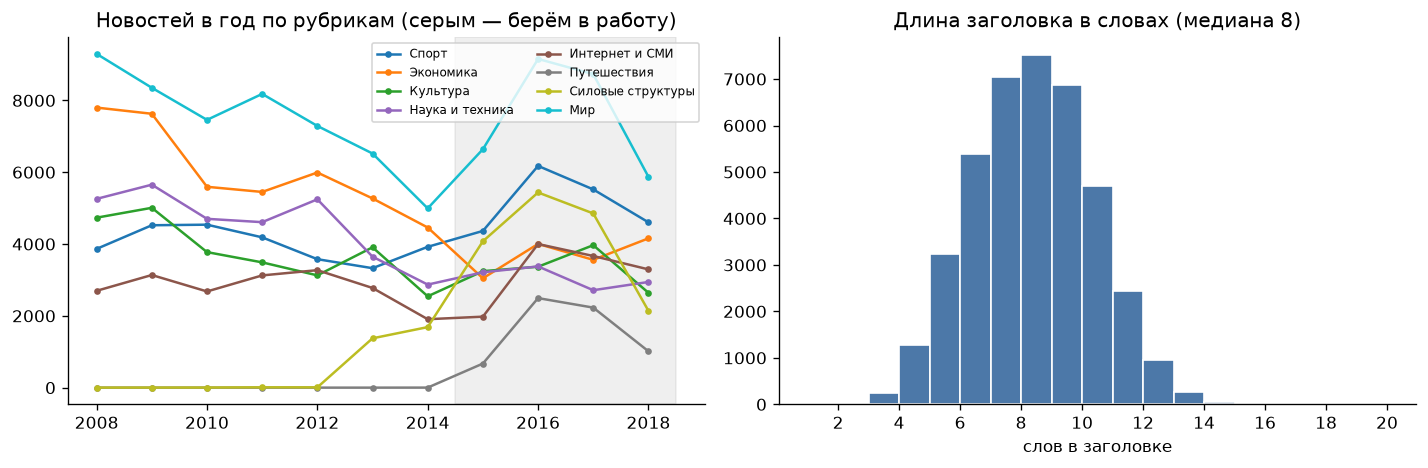

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_year = pd.crosstab(raw["year"], raw["topic"]).loc[2008:2018, TOPICS]
by_year.plot(ax=axes[0], marker="o", ms=3, lw=1.5, cmap="tab10")
axes[0].axvspan(2014.5, 2018.5, color="grey", alpha=0.12)
axes[0].set_title("Новостей в год по рубрикам (серым — берём в работу)")
axes[0].set_xlabel("")
axes[0].legend(fontsize=7, ncol=2)

df["n_words"] = df["title"].str.split().str.len()
axes[1].hist(df["n_words"], bins=range(1, 21), color="#4C78A8", edgecolor="white")
axes[1].set_title(f"Длина заголовка в словах (медиана {df['n_words'].median():.0f})")
axes[1].set_xticks(range(2, 21, 2))
axes[1].set_xlabel("слов в заголовке")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_data.png", bbox_inches="tight")
plt.show()

In [92]:
pd.set_option("display.max_colwidth", 120)
df.groupby("topic").sample(2, random_state=SEED)[["topic", "title"]]

,topic,title
1501,Интернет и СМИ,Эксперт призвал контролировать Telegram для борьбы с терроризмом и наркоманией
2586,Интернет и СМИ,Анонсирован запуск машины для поиска сохраненного порно
6078,Культура,Warner Bros. переснимет первую «Матрицу»
7889,Культура,Фильм про Довлатова получил приз независимого жюри Берлинале
11105,Мир,Мужчина перерезал горло бывшей жене в торговом центре в Мексике
11176,Мир,В США предложили убрать с банкнот фразу In God We Trust
17077,Наука и техника,Представлена программа мероприятий Года науки Великобритании и России
18032,Наука и техника,НАСА опубликовало снимок центра Млечного Пути
23902,Путешествия,Самолет экстренно посадили из-за невыносимого запаха
24338,Путешествия,Путин обозначил условия возобновления полетов в Египет


## Наивный Байес своими руками

Для заголовка из слов w1, ..., wn выбираем рубрику c, у которой больше всего

log P(c) + log P(w1 | c) + ... + log P(wn | c)

- P(c) — доля рубрики в обучающей выборке;
- P(w | c) = (сколько раз слово w встретилось в рубрике c + α) / (всего слов в рубрике c + α · размер словаря).

«Наивность» в том, что слова считаются независимыми друг от друга при известной рубрике.
Логарифмы нужны, чтобы произведение маленьких вероятностей не превратилось в ноль.
α — сглаживание Лапласа: без него одно незнакомое для рубрики слово обнуляет всю вероятность.

In [93]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["title"], df["topic"].to_numpy(),
    test_size=0.2, stratify=df["topic"], random_state=SEED)

vectorizer = CountVectorizer(lowercase=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Обучение:", X_train.shape, " тест:", X_test.shape)
print("Размер словаря:", len(vectorizer.vocabulary_))

Обучение: (32000, 45323)  тест: (8000, 45323)
Размер словаря: 45323


In [94]:
class MyMultinomialNB:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_classes, n_words = len(self.classes_), X.shape[1]

        self.class_log_prior_ = np.zeros(n_classes)
        word_counts = np.zeros((n_classes, n_words))

        for i, c in enumerate(self.classes_):
            X_c = X[y == c]
            self.class_log_prior_[i] = np.log(X_c.shape[0] / X.shape[0])
            word_counts[i] = np.asarray(X_c.sum(axis=0)).ravel()

        smoothed = word_counts + self.alpha
        self.feature_log_prob_ = np.log(smoothed / smoothed.sum(axis=1, keepdims=True))
        return self

    def joint_log_proba(self, X):
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    def predict(self, X):
        return self.classes_[np.argmax(self.joint_log_proba(X), axis=1)]

In [95]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score

t0 = time.perf_counter()
my_nb = MyMultinomialNB(alpha=1.0).fit(X_train, y_train)
t_my = time.perf_counter() - t0

t0 = time.perf_counter()
sk_nb = MultinomialNB(alpha=1.0).fit(X_train, y_train)
t_sk = time.perf_counter() - t0

my_pred = my_nb.predict(X_test)
sk_pred = sk_nb.predict(X_test)

print(f"Своя реализация: accuracy = {accuracy_score(y_test, my_pred):.4f}, "
      f"macro-F1 = {f1_score(y_test, my_pred, average='macro'):.4f}, обучение {t_my*1000:.0f} мс")
print(f"sklearn:         accuracy = {accuracy_score(y_test, sk_pred):.4f}, "
      f"macro-F1 = {f1_score(y_test, sk_pred, average='macro'):.4f}, обучение {t_sk*1000:.0f} мс")
print("Вероятности слов совпадают:", np.allclose(my_nb.feature_log_prob_, sk_nb.feature_log_prob_))
print("Предсказания совпадают:", (my_pred == sk_pred).mean() * 100, "%")
print("Случайное угадывание:", 1 / len(TOPICS))

Своя реализация: accuracy = 0.7893, macro-F1 = 0.7890, обучение 116 мс
sklearn:         accuracy = 0.7893, macro-F1 = 0.7890, обучение 276 мс
Вероятности слов совпадают: True
Предсказания совпадают: 100.0 %
Случайное угадывание: 0.125


## Маленький пример руками

Обучающая выборка из пяти заголовков:

| Заголовок | Рубрика |
| --- | --- |
| Спартак выиграл матч | Спорт |
| Матч перенесли | Спорт |
| Рубль упал | Экономика |
| Рубль вырос | Экономика |
| Нефть упала | Экономика |

Новый заголовок: **«Рубль выиграл»**. Слово «рубль» было только в экономике, «выиграл» — только в спорте.

1. Априорные вероятности: P(Спорт) = 2/5, P(Экономика) = 3/5.
2. Словарь: 9 слов. Всего слов в спорте — 5, в экономике — 6. Сглаживание α = 1.
3. Вероятности слов:
   - P(рубль | Спорт) = (0 + 1) / (5 + 9) = 1/14,  P(выиграл | Спорт) = (1 + 1) / 14 = 2/14
   - P(рубль | Экономика) = (2 + 1) / (6 + 9) = 3/15,  P(выиграл | Экономика) = (0 + 1) / 15 = 1/15
4. Оценки:
   - Спорт: 2/5 · 1/14 · 2/14 ≈ 0.00408
   - Экономика: 3/5 · 3/15 · 1/15 = 0.00800
5. После нормировки: Экономика ≈ 0.662, Спорт ≈ 0.338. Ответ: **Экономика**.

Без сглаживания обе оценки были бы равны нулю (у каждой рубрики одно из слов встречается 0 раз), и модель не смогла бы выбрать.

In [96]:
toy_titles = ["Спартак выиграл матч", "Матч перенесли",
              "Рубль упал", "Рубль вырос", "Нефть упала"]
toy_y = np.array(["Спорт", "Спорт", "Экономика", "Экономика", "Экономика"])

toy_vec = CountVectorizer()
toy_X = toy_vec.fit_transform(toy_titles)

pd.DataFrame(toy_X.toarray(), columns=toy_vec.get_feature_names_out(), index=toy_y)

,выиграл,вырос,матч,нефть,перенесли,рубль,спартак,упал,упала
Спорт,1,0,1,0,0,0,1,0,0
Спорт,0,0,1,0,1,0,0,0,0
Экономика,0,0,0,0,0,1,0,1,0
Экономика,0,1,0,0,0,1,0,0,0
Экономика,0,0,0,1,0,0,0,0,1


In [97]:
toy_nb = MyMultinomialNB(alpha=1.0).fit(toy_X, toy_y)
x_new = toy_vec.transform(["Рубль выиграл"])

scores = np.exp(toy_nb.joint_log_proba(x_new)).ravel()
for c, s in zip(toy_nb.classes_, scores):
    print(f"{c:10s} оценка = {s:.5f}   вероятность = {s / scores.sum():.3f}")

sk_toy = MultinomialNB(alpha=1.0).fit(toy_X, toy_y)
print("sklearn:", {str(c): round(float(p), 3)
                   for c, p in zip(sk_toy.classes_, sk_toy.predict_proba(x_new).ravel())})

Спорт      оценка = 0.00408   вероятность = 0.338
Экономика  оценка = 0.00800   вероятность = 0.662
sklearn: {'Спорт': 0.338, 'Экономика': 0.662}


## Сравнение с другими моделями

Все модели получают одни и те же признаки (мешок слов) и одно и то же разбиение.

- **ComplementNB** — вариант наивного Байеса: оценивает слова по всем рубрикам, *кроме* данной. Часто лучше на текстах.
- **Логистическая регрессия** — линейная модель, веса подбираются оптимизацией, а не подсчётом частот.
- **Линейный SVM** — тоже линейная модель, максимизирует зазор между классами.
- **kNN** — ищет 10 самых похожих заголовков из обучения и голосует.

In [106]:
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

models = {
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "ComplementNB": ComplementNB(alpha=1.0),
    "Логистическая регрессия": LogisticRegression(max_iter=2000),
    "Линейный SVM": LinearSVC(),
    "kNN (k=10, косинус)": KNeighborsClassifier(n_neighbors=10, metric="cosine"),
}

rows = []
def timed(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return out, float(np.median(times))

rows = []
for name, model in models.items():
    _, t_fit = timed(lambda: model.fit(X_train, y_train))
    pred, t_pred = timed(lambda: model.predict(X_test))
    rows.append({"модель": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "macro-F1": f1_score(y_test, pred, average="macro"),
                 "обучение, с": t_fit,
                 "предсказание, с": t_pred,
                 "всего, с": t_fit + t_pred})

results = pd.DataFrame(rows).set_index("модель").sort_values("macro-F1", ascending=False)
results.round(3)

,accuracy,macro-F1,"обучение, с","предсказание, с","всего, с"
модель,,,,,
ComplementNB,0.810,0.809,0.071,0.003,0.074
Линейный SVM,0.798,0.798,0.747,0.001,0.748
Логистическая регрессия,0.797,0.797,5.455,0.001,5.456
MultinomialNB,0.789,0.789,0.062,0.005,0.068
"kNN (k=10, косинус)",0.651,0.650,0.034,5.103,5.138


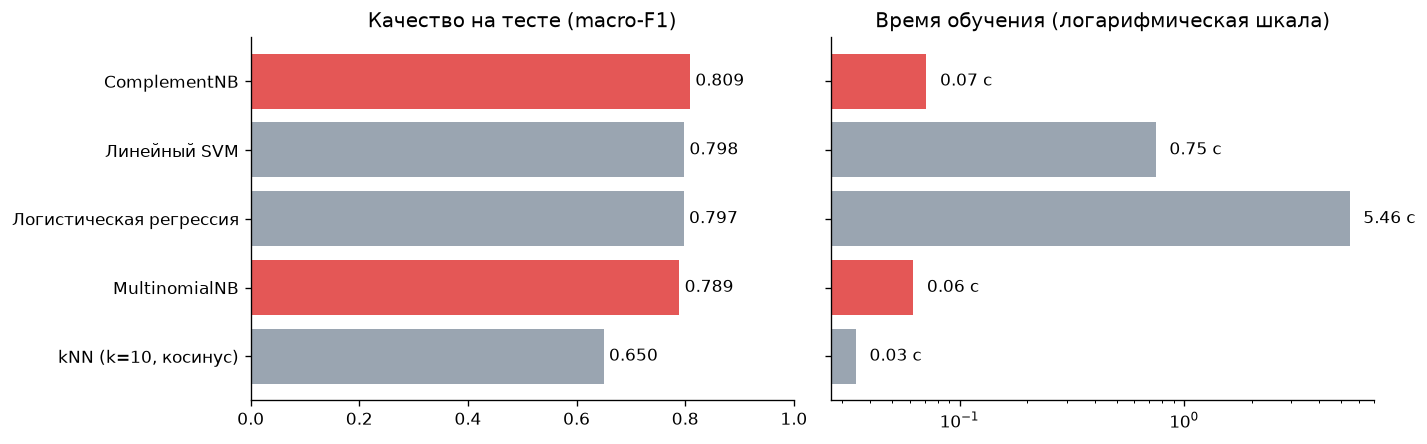

In [ ]:
order = results.index[::-1]
colors = ["#E45756" if "NB" in m else "#9AA5B1" for m in order]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)

f1 = results.loc[order, "macro-F1"]
axes[0].barh(order, f1, color=colors)
for i, v in enumerate(f1):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center")
axes[0].set_xlim(0, 1)
axes[0].set_title("Качество на тесте (macro-F1)")

t_total = results.loc[order, "всего, с"]
axes[1].barh(order, t_total, color=colors)
for i, v in enumerate(t_total):
    axes[1].text(v * 1.15, i, f"{v:.2f} с", va="center")
axes[1].set_xscale("log")
axes[1].set_title("Время: обучение + предсказание (медиана 3 запусков)")

fig.tight_layout()
fig.savefig(FIG_DIR / "02_models.png", bbox_inches="tight")
plt.show()

## Что выучила модель

Модель — это просто таблица P(слово | рубрика). Посмотрим, какие слова в ней «самые важные» для каждой рубрики.

In [108]:
words = vectorizer.get_feature_names_out()
log_p = sk_nb.feature_log_prob_

pd.DataFrame({c: words[np.argsort(log_p[i])[::-1][:8]]
              for i, c in enumerate(sk_nb.classes_)}).T

,0,1,2,3,4,5,6,7
Интернет и СМИ,на,за,из,сети,для,от,россии,по
Культура,на,из,за,умер,фильма,трейлер,вышел,актер
Мир,на,сша,за,из,по,россии,сирии,иг
Наука и техника,на,сша,для,ученые,нашли,россии,из,от
Путешествия,на,за,из,туристов,для,россии,россиян,по
Силовые структуры,на,за,по,из,россии,москве,минобороны,суд
Спорт,на,за,россии,по,из,сборной,от,мира
Экономика,на,россии,за,рублей,по,из,до,от


In [109]:
counts = np.asarray(X_train.sum(axis=0)).ravel()
frequent = counts >= 20   # убираем редкие слова, они дают шум

top = {}
for i, c in enumerate(sk_nb.classes_):
    others = np.delete(log_p, i, axis=0).mean(axis=0)
    score = np.where(frequent, log_p[i] - others, -np.inf)
    top[c] = words[np.argsort(score)[::-1][:8]]

pd.DataFrame(top).T

,0,1,2,3,4,5,6,7
Интернет и СМИ,пользователей,telegram,facebook,роскомнадзор,вконтакте,блогер,google,twitter
Культура,актер,трейлер,режиссер,фильм,престолов,альбом,сериал,актриса
Мир,оон,иг,погибли,боевики,сирии,лавров,меркель,трамп
Наука и техника,ученые,наса,мкс,опасность,мгу,spacex,apple,falcon
Путешествия,туристов,туристы,турист,туристам,туриста,отдых,авиакомпания,направления
Силовые структуры,минобороны,колонии,скр,немцова,подмосковье,возбудили,ск,сизо
Спорт,сборной,футболист,сборная,мутко,тренер,роналду,фифа,кубка
Экономика,цб,доллара,курс,минфин,нефть,мвф,нефти,рубля


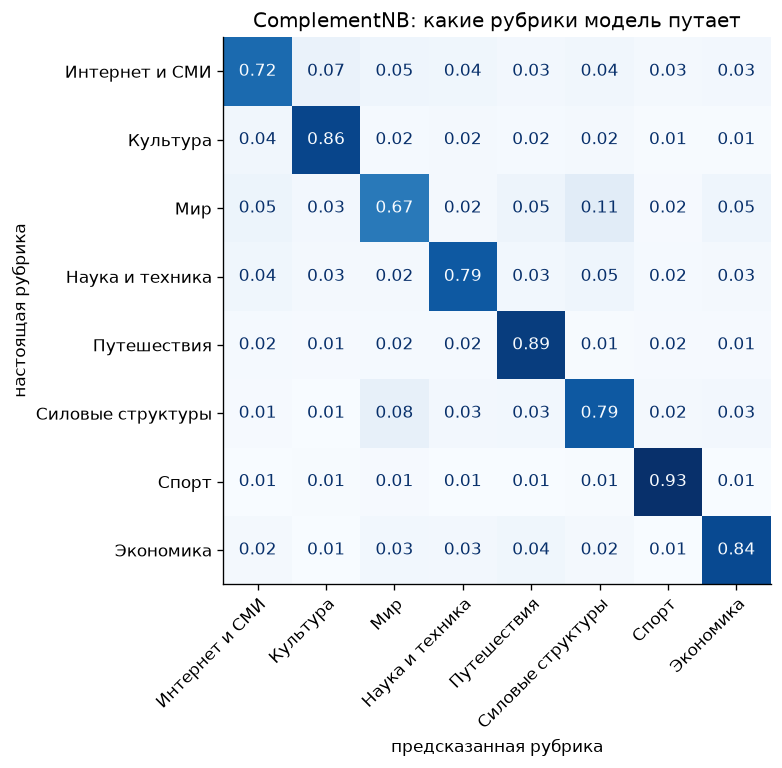

In [110]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_estimator(
    models["ComplementNB"], X_test, y_test,
    normalize="true", values_format=".2f", cmap="Blues",
    colorbar=False, xticks_rotation=45, ax=ax)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
ax.set_title("ComplementNB: какие рубрики модель путает")
ax.set_xlabel("предсказанная рубрика")
ax.set_ylabel("настоящая рубрика")

fig.tight_layout()
fig.savefig(FIG_DIR / "04_confusion.png", bbox_inches="tight")
plt.show()


## Демо: угадай рубрику

In [111]:
analyzer = vectorizer.build_analyzer()

def explain(title, model=sk_nb, top_k=3):
    x = vectorizer.transform([title])
    proba = model.predict_proba(x).ravel()
    print(f"«{title}»")
    for j in np.argsort(proba)[::-1][:top_k]:
        print(f"  {model.classes_[j]:18s} {proba[j]:.1%}")

    tokens = analyzer(title)
    for w in tokens:
        if w in vectorizer.vocabulary_:
            k = vectorizer.vocabulary_[w]
            lead = model.classes_[np.argmax(model.feature_log_prob_[:, k])]
            print(f"    {w:15s} -> тянет к «{lead}»")
    unknown = [w for w in tokens if w not in vectorizer.vocabulary_]
    if unknown:
        print("    незнакомые слова (не влияют):", ", ".join(unknown))
    print()

for t in ["Сборная России вышла в финал чемпионата мира",
          "ЦБ повысил ключевую ставку",
          "Ученые нашли воду на Марсе",
          "Хакеры взломали серверы банка"]:
    explain(t)

«Сборная России вышла в финал чемпионата мира»
  Спорт              100.0%
  Культура           0.0%
  Путешествия        0.0%
    сборная         -> тянет к «Спорт»
    россии          -> тянет к «Экономика»
    вышла           -> тянет к «Спорт»
    финал           -> тянет к «Спорт»
    чемпионата      -> тянет к «Спорт»
    мира            -> тянет к «Спорт»

«ЦБ повысил ключевую ставку»
  Экономика          100.0%
  Интернет и СМИ     0.0%
  Наука и техника    0.0%
    цб              -> тянет к «Экономика»
    повысил         -> тянет к «Экономика»
    ключевую        -> тянет к «Экономика»
    ставку          -> тянет к «Экономика»

«Ученые нашли воду на Марсе»
  Наука и техника    100.0%
  Мир                0.0%
  Путешествия        0.0%
    ученые          -> тянет к «Наука и техника»
    нашли           -> тянет к «Наука и техника»
    воду            -> тянет к «Наука и техника»
    на              -> тянет к «Путешествия»
    марсе           -> тянет к «Наука и техника»

«